In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [20]:
df = pd.read_csv('./bike_train.csv')
print(df.shape)
df.head()

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [22]:
df['datetime'] = df.datetime.apply(pd.to_datetime)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(8)
memory usage: 1020.7 KB


In [23]:
df['year'] = df.datetime.apply(lambda x: x.year)
df['month'] = df.datetime.apply(lambda x: x.month)
df['day'] = df.datetime.apply(lambda x: x.day)
df['hour'] = df.datetime.apply(lambda x: x.hour)
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011,1,1,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011,1,1,4


In [24]:
drop_columns = ['datetime', 'casual', 'registered']
df.drop(drop_columns, axis=1, inplace=True)

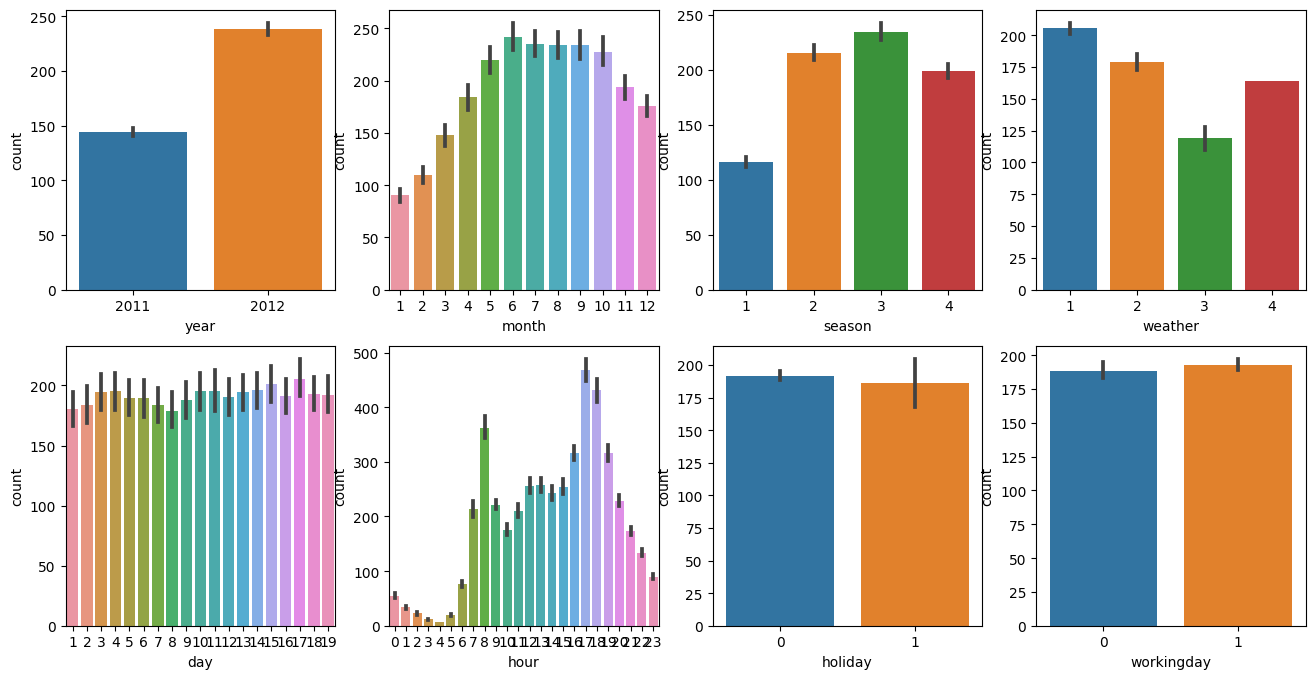

In [25]:
fig, axs = plt.subplots(figsize = (16, 8), ncols = 4, nrows = 2)
cat_features = ['year', 'month', 'season', 'weather', 'day', 'hour', 'holiday', 'workingday']

for i, feature in enumerate(cat_features):
    row = int(i / 4)
    col = i % 4
    sns.barplot(x = feature, y = 'count', data = df, ax = axs[row][col])

In [26]:
# 성능평가지표 함수
from sklearn.metrics import mean_squared_error, mean_absolute_error

def rmsle(y, pred):
    log_y = np.log1p(y)
    log_pred = np.log1p(pred)
    squared_error = (log_y - log_pred) ** 2
    # 들어오는 값 중 NaN이 있을 경우 대비
    rmsle = np.sqrt(np.mean(squared_error))
    return rmsle

def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

def evaluate_regr(y, pred):
    rmsle_val = rmsle(y, pred)
    rmse_val = rmse(y, pred)
    mae_val = mean_absolute_error(y, pred)
    print(np.round(rmsle_val, 3), np.round(rmse_val, 3), np.round(mae_val, 3))

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso

y_target = df['count']
X_features = df.drop(['count'], axis = 1)

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.3, random_state=42)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

evaluate_regr(y_test, pred)

1.174 141.261 105.676


In [28]:
def get_top_error_data(y_test, pred, n_tops=5):
    res_df = pd.DataFrame(y_test.values, columns=['real_count'])
    res_df['pred_count'] = np.round(pred)
    res_df['diff'] = np.abs(res_df['real_count'] - res_df['pred_count'])
    print(res_df.sort_values('diff', ascending=False)[: n_tops])

get_top_error_data(y_test, pred, n_tops=5)

      real_count  pred_count   diff
1094         977       391.0  586.0
361          948       366.0  582.0
1872         890       325.0  565.0
1654         888       327.0  561.0
1841         884       326.0  558.0


<Axes: >

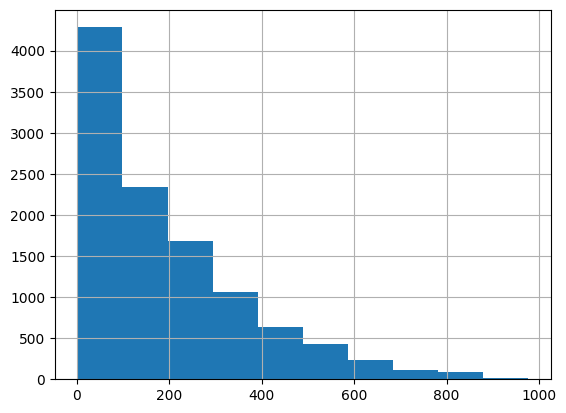

In [29]:
y_target.hist()
# 값의 차이가 크기에 다음 셀에서 log로 변환

<Axes: >

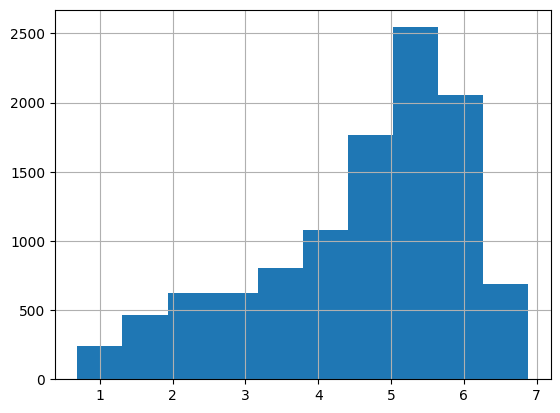

In [30]:
y_log_transform = np.log1p(y_target)
y_log_transform.hist()
# 로그 변환을 해줬더니 한눈에 들어오기 좋은 값으로 변했다.

In [31]:
y_target_log = np.log1p(y_target)

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target_log, test_size=0.3, random_state=42)
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

y_test_exp = np.expm1(y_test)

pred_exp = np.expm1(pred)

evaluate_regr(y_test_exp, pred_exp)

1.02 160.73 108.236


<Axes: >

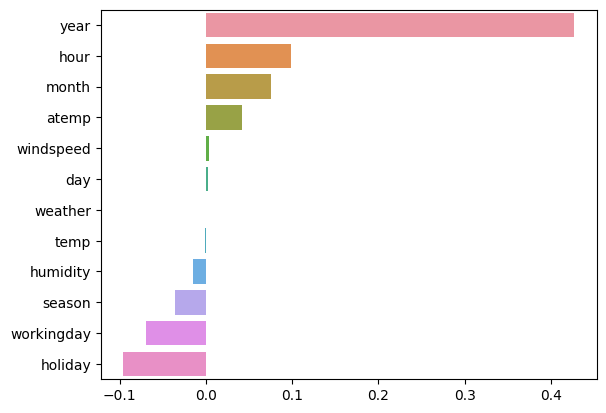

In [32]:
# 회귀는 하고 난 후 출력값 확인 필수
coef = pd.Series(lr_reg.coef_, index = X_features.columns)
coef_sort = coef.sort_values(ascending=False)
sns.barplot(x=coef_sort.values, y=coef_sort.index)

In [33]:
# 원핫인코딩

X_features_ohe = pd.get_dummies(X_features, columns= [ "year", "month", "day", "hour", "holiday", "workingday", "season", "weather"])

In [38]:
X_train , X_test , y_train , y_test  = train_test_split( X_features_ohe , y_target_log, test_size=0.3 , random_state= 42)

def get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=False):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    if is_expm1:
        y_test = np.expm1(y_test)
        pred = np.expm1(pred)

    print("###", model.__class__.__name__, "###")
    evaluate_regr(y_test, pred)


lr_reg = LinearRegression()
ridge_reg = Ridge(alpha =10)
lasso_reg = Lasso(alpha= 0.01)

for model in [lr_reg, ridge_reg, lasso_reg]:
    get_model_predict(model, X_train, X_test, y_train, y_test,is_expm1 = True)

### LinearRegression ###
0.585 95.845 62.352
### Ridge ###
0.587 96.827 62.889
### Lasso ###
0.639 112.044 71.914


<Axes: >

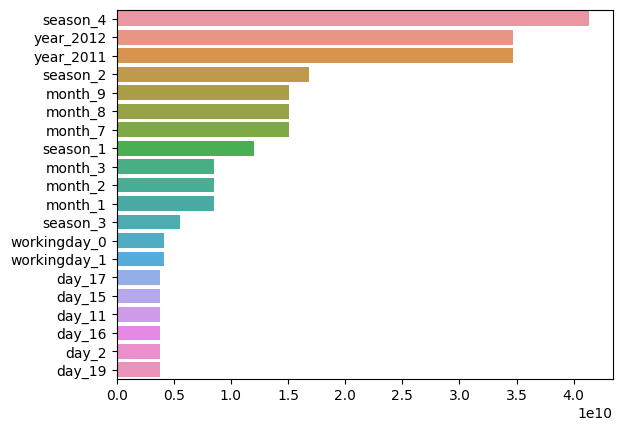

In [39]:
coef = pd.Series(lr_reg.coef_, index = X_features_ohe.columns)
coef_sort = coef.sort_values(ascending = False)[:20]
sns.barplot(x = coef_sort.values, y = coef_sort.index)

In [41]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRFRegressor
from lightgbm import LGBMRegressor

rf = RandomForestRegressor(n_estimators= 500)
gbm = GradientBoostingRegressor(n_estimators=500)
xgb = XGBRFRegressor(n_estimators = 500)
lgbm = LGBMRegressor(n_estimators= 500)

for model in [rf , gbm, xgb, lgbm]:
    get_model_predict(model, X_train.values, X_test.values,y_train.values, y_test.values,is_expm1=True)

### RandomForestRegressor ###
0.349 47.962 30.013
### GradientBoostingRegressor ###
0.331 51.742 32.219
### XGBRFRegressor ###
0.792 156.908 100.173
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000334 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 347
[LightGBM] [Info] Number of data points in the train set: 7620, number of used features: 72
[LightGBM] [Info] Start training from score 4.585795
### LGBMRegressor ###
0.314 44.509 27.586
